# EDA — Perovskite Solar Cell (process-focused)

สำรวจข้อมูลที่ผ่านการ re-schema แล้ว (ดู [`RESCHEMA_README.md`](../RESCHEMA_README.md)):
- `processed/ml_dataset.csv` — 1 แถว/device (feature matrix พร้อม ML)
- `processed/csv/*.csv` — ตาราง normalized (source of truth)

โฟกัสของ EDA นี้:
1. ภาพรวม dataset + **missing data**
2. การกระจายของ target (PCE) และ JV metrics
3. **Data-quality flags** ที่ต้องแก้ก่อนเทรนโมเดล
4. Features เชิงโครงสร้าง/กระบวนการ (จุดเด่นของโปรเจกต์)
5. ความสัมพันธ์ระหว่าง process → performance
6. ความเสถียร (stability)

> ข้อความในกราฟเป็นภาษาอังกฤษ; สี chart ใช้ palette ที่ผ่านการตรวจ colorblind-safe แล้ว

## Setup & style

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

ROOT = os.path.abspath(os.path.join(os.getcwd(), ".." if os.path.basename(os.getcwd())=="notebooks" else "."))
os.chdir(ROOT)

# --- validated categorical palette (fixed order, colorblind-safe) ---
CAT = ["#2a78d6", "#1baf7a", "#eda100", "#008300",
       "#4a3aa7", "#e34948", "#e87ba4", "#eb6834"]
BLUE = "#2a78d6"
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
# diverging colormap (blue <-> gray <-> red) for correlation (polarity)
DIVERGING = LinearSegmentedColormap.from_list("bwr_cvd", ["#2a78d6", "#f0efec", "#e34948"])

plt.rcParams.update({
    "axes.unicode_minus": False,
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.titlecolor": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold",
    "figure.dpi": 110,
})

def style(ax, title=None, xlabel=None, ylabel=None):
    if title: ax.set_title(title, loc="left", pad=10)
    if xlabel is not None: ax.set_xlabel(xlabel)
    if ylabel is not None: ax.set_ylabel(ylabel)
    ax.grid(axis="x", visible=False)
    return ax

ml = pd.read_csv("processed/ml_dataset.csv")
tables = {t: pd.read_csv(f"processed/csv/{t}.csv")
          for t in ["devices","layers","vendors","materials","process","properties","stability"]}
print("ml_dataset:", ml.shape)

Matplotlib is building the font cache; this may take a moment.


ml_dataset: (44, 17)


## ภาพรวม dataset

In [2]:
print(f"{ml.shape[0]} devices | {ml['doi_raw'].nunique()} publications\n")
print("normalized table sizes:")
for t, df in tables.items():
    print(f"  {t:12s} {df.shape}")
ml.head()

44 devices | 15 publications

normalized table sizes:
  devices      (44, 4)
  layers       (352, 5)
  vendors      (644, 4)
  materials    (543, 7)
  process      (702, 9)
  properties   (563, 6)
  stability    (62, 10)


,device_id,doi_raw,sample_no,n_layers,htl_material,etl_material,perovskite,anode,cathode,n_process_steps,n_spin_coating,has_antisolvent,bandgap_max,ff_max,jsc_max,pce_max,voc_max
0,10.1002admi.202500231_Sample1,10.1002admi.202500231,1,6,NiOx NPs,C60,[ (Cs.05FA.79MA.16)Pb(I.87Br.13)3 ],ITO,Ag,18,3,True,3.85,0.76,20.97,16.31,1.020
1,10.1002admi.202500231_Sample2,10.1002admi.202500231,2,7,NiOx NPs,C60,[ (Cs.05FA.79MA.16)Pb(I.87Br.13)3 ],ITO,Ag,19,3,True,3.85,0.75,22.01,17.11,1.040
2,10.1002admi.202500231_Sample3,10.1002admi.202500231,3,7,NiOx NPs,C60,[ (Cs.05FA.79MA.16)Pb(I.87Br.13)3 ],ITO,Ag,19,3,True,3.85,0.78,21.86,16.97,1.000
3,10.1002admi.202500231_Sample4,10.1002admi.202500231,4,7,NiOx NPs,C60,[ (Cs.05FA.79MA.16)Pb(I.87Br.13)3 ],ITO,Ag,19,3,True,3.85,0.79,20.79,16.25,0.990
4,10.1016j.jechem.2021.11.029_Sample1,10.1016j.jechem.2021.11.029,1,7,NiOx,PCBM,(FA0.85MA0.15)0.95Cs0.05Pb(I0.85Br0.15)3,ITO,Ag,13,6,True,NaN,79.60,21.32,17.83,1.065


In [3]:
ml.describe(include="number").T.round(2)

,count,mean,std,min,25%,50%,75%,max
sample_no,44.0,2.16,1.14,1.00,1.00,2.00,3.00,5.00
n_layers,44.0,7.11,0.75,6.00,7.00,7.00,8.00,8.00
n_process_steps,44.0,15.34,2.27,11.00,14.00,15.00,16.25,20.00
n_spin_coating,44.0,4.84,1.31,3.00,4.00,5.00,6.00,7.00
bandgap_max,6.0,3.27,1.40,0.42,3.81,3.85,3.85,3.85
ff_max,43.0,67.33,27.49,0.71,71.50,78.21,81.19,84.68
jsc_max,43.0,23.15,2.14,18.26,21.36,23.49,24.72,26.55
pce_max,43.0,20.01,3.45,13.98,17.20,20.16,22.78,26.50
voc_max,43.0,1.10,0.07,0.97,1.04,1.11,1.15,1.24


## Missing data

ก่อนเทรนต้องรู้ว่าคอลัมน์ไหนมีค่าไม่ครบ. เห็นชัดว่า `bandgap_max` แทบว่าง
(และค่าที่มีก็ปนกันระหว่าง band gap ของ perovskite กับของ HTL — ดูหัวข้อ Data-quality flags).

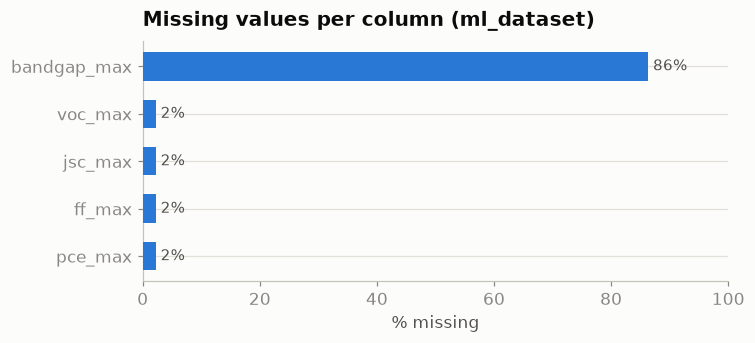

In [4]:
miss = ml.isna().mean().mul(100).sort_values()
miss = miss[miss > 0]
fig, ax = plt.subplots(figsize=(7, max(2, 0.45*len(miss)+1)))
ax.barh(miss.index, miss.values, color=BLUE, height=0.6, zorder=3)
for y, v in enumerate(miss.values):
    ax.text(v+0.8, y, f"{v:.0f}%", va="center", color=INK2, fontsize=10)
ax.set_xlim(0, 100)
style(ax, "Missing values per column (ml_dataset)", "% missing", None)
plt.tight_layout(); plt.show()

## การกระจายของ PCE (target) และ JV metrics

PCE คือ target หลักของการทำนายประสิทธิภาพจากกระบวนการ.

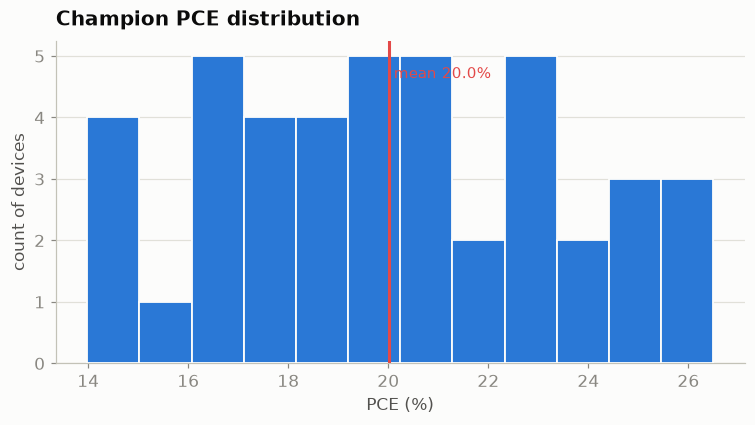

In [5]:
pce = ml["pce_max"].dropna()
fig, ax = plt.subplots(figsize=(7,4))
ax.hist(pce, bins=12, color=BLUE, edgecolor="#fcfcfb", linewidth=1.2, zorder=3)
ax.axvline(pce.mean(), color="#e34948", lw=2, zorder=4)
ax.text(pce.mean(), ax.get_ylim()[1]*0.92, f" mean {pce.mean():.1f}%",
        color="#e34948", fontsize=10, va="top")
style(ax, "Champion PCE distribution", "PCE (%)", "count of devices")
plt.tight_layout(); plt.show()

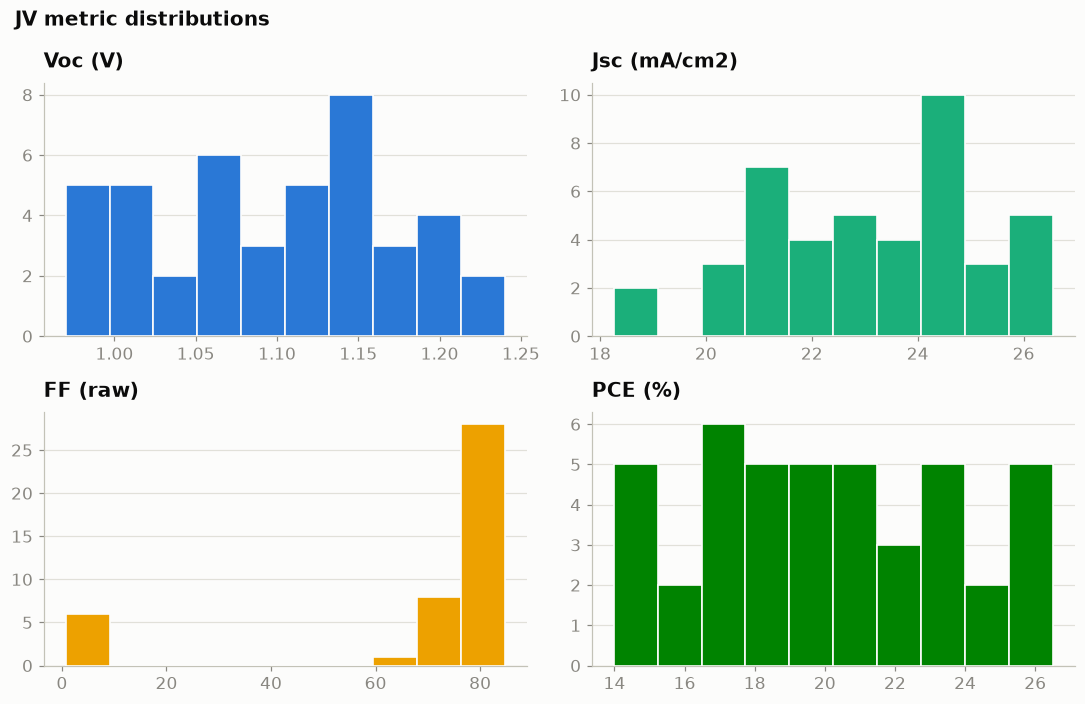

In [6]:
# small multiples of JV metrics
metrics = [("voc_max","Voc (V)"), ("jsc_max","Jsc (mA/cm2)"),
           ("ff_max","FF (raw)"), ("pce_max","PCE (%)")]
fig, axes = plt.subplots(2, 2, figsize=(10,6.5))
for (col, label), ax, c in zip(metrics, axes.ravel(), CAT):
    d = ml[col].dropna()
    ax.hist(d, bins=10, color=c, edgecolor="#fcfcfb", linewidth=1.1, zorder=3)
    style(ax, label, None, None)
    ax.grid(axis="x", visible=False)
fig.suptitle("JV metric distributions", x=0.02, ha="left", fontweight="bold", fontsize=13)
plt.tight_layout(); plt.show()

## ⚠️ Data-quality flags (ต้องแก้ก่อนเทรน)

EDA เจอปัญหาที่ยัง**ไม่ได้ clean** (สอดคล้องกับที่คุยไว้ว่ายังไม่ได้จัดการ missing/หน่วย):

1. **`ff_max` ปนหน่วย** — บางค่าเก็บเป็นเศษส่วน (0.7x) บางค่าเป็นเปอร์เซ็นต์ (7x–8x)
2. **`bandgap_max` ปนความหมาย** — ค่า 3.85 ซ้ำ ๆ คือ band gap ของ HTL (NiOx) ไม่ใช่ perovskite
3. **ชื่อวัสดุ HTL ซ้ำหลายแบบ** — `NiOx`, `NiOx NPs`, `NiOx Nanoparticles` = ตัวเดียวกัน

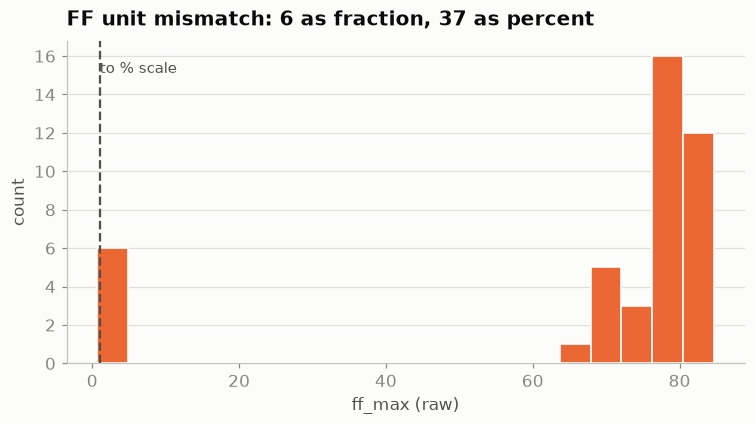

FF values stored as fraction: [0.71, 0.72, 0.75, 0.76, 0.78, 0.79]


In [7]:
# 1) FF: fraction vs percent
ff = ml["ff_max"].dropna()
frac = int((ff < 1).sum()); pct = int((ff >= 1).sum())
fig, ax = plt.subplots(figsize=(7,4))
ax.hist(ff, bins=20, color="#eb6834", edgecolor="#fcfcfb", linewidth=1.1, zorder=3)
ax.axvline(1, color=INK2, lw=1.5, ls="--", zorder=4)
ax.text(1.02, ax.get_ylim()[1]*0.9, "to % scale", color=INK2, fontsize=10)
style(ax, f"FF unit mismatch: {frac} as fraction, {pct} as percent", "ff_max (raw)", "count")
plt.tight_layout(); plt.show()
print("FF values stored as fraction:", sorted(ff[ff<1].round(3).tolist()))

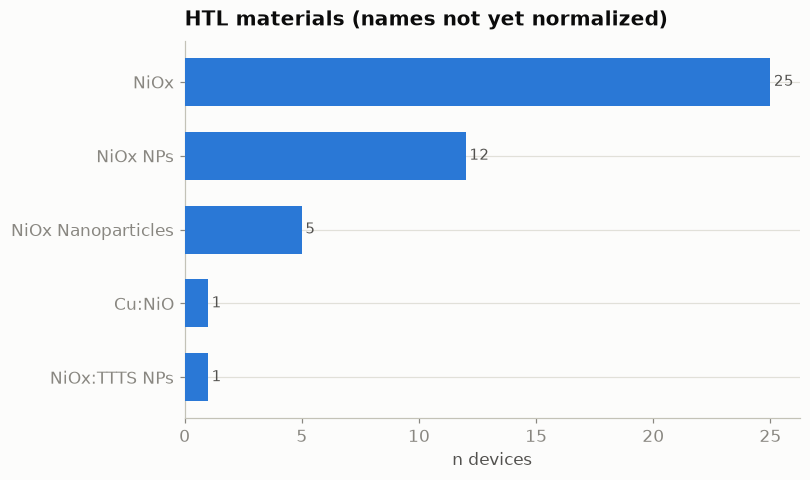

In [8]:
# 3) HTL material name variants
htl = tables["layers"].query("layer_type == 'HTL'")["material"].dropna()
vc = htl.value_counts().head(12)
fig, ax = plt.subplots(figsize=(7.5,4.5))
ax.barh(vc.index[::-1], vc.values[::-1], color=BLUE, height=0.65, zorder=3)
for y, v in enumerate(vc.values[::-1]):
    ax.text(v+0.15, y, str(v), va="center", color=INK2, fontsize=10)
style(ax, "HTL materials (names not yet normalized)", "n devices", None)
plt.tight_layout(); plt.show()

## Features เชิงกระบวนการ (จุดเด่นของโปรเจกต์)

โปรเจกต์เน้น *process* — ดูความซับซ้อนของกระบวนการและเทคนิคที่ใช้.

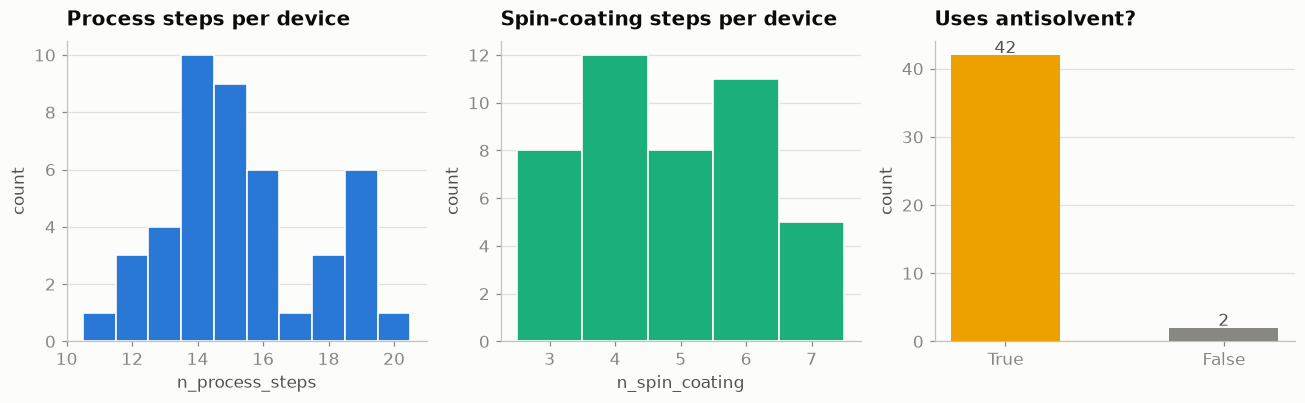

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(12,3.8))
# n_process_steps
d = ml["n_process_steps"]
axes[0].hist(d, bins=range(d.min(), d.max()+2), color=CAT[0], align="left",
             edgecolor="#fcfcfb", linewidth=1.1, zorder=3)
style(axes[0], "Process steps per device", "n_process_steps", "count")
axes[0].grid(axis="x", visible=False)
# n_spin_coating
d2 = ml["n_spin_coating"]
axes[1].hist(d2, bins=range(d2.min(), d2.max()+2), color=CAT[1], align="left",
             edgecolor="#fcfcfb", linewidth=1.1, zorder=3)
style(axes[1], "Spin-coating steps per device", "n_spin_coating", "count")
axes[1].grid(axis="x", visible=False)
# has_antisolvent
av = ml["has_antisolvent"].value_counts()
axes[2].bar([str(i) for i in av.index], av.values, color=[CAT[2], MUTED], width=0.5, zorder=3)
for i, v in enumerate(av.values):
    axes[2].text(i, v+0.3, str(v), ha="center", color=INK2)
style(axes[2], "Uses antisolvent?", None, "count")
axes[2].grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

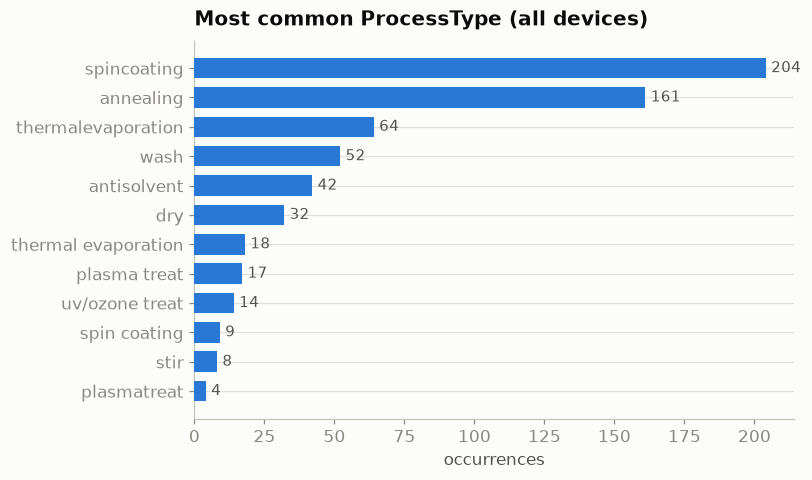

In [10]:
# most common process types (from the long `process` table)
pt = tables["process"]["process_type"].dropna().str.strip().str.lower().value_counts().head(12)
fig, ax = plt.subplots(figsize=(7.5,4.5))
ax.barh(pt.index[::-1], pt.values[::-1], color=BLUE, height=0.7, zorder=3)
for y, v in enumerate(pt.values[::-1]):
    ax.text(v+2, y, str(v), va="center", color=INK2, fontsize=10)
style(ax, "Most common ProcessType (all devices)", "occurrences", None)
plt.tight_layout(); plt.show()

## Correlation ระหว่าง numeric features

หา multicollinearity และตัวแปรที่สัมพันธ์กับ PCE. (diverging colormap: น้ำเงิน = +, แดง = −)

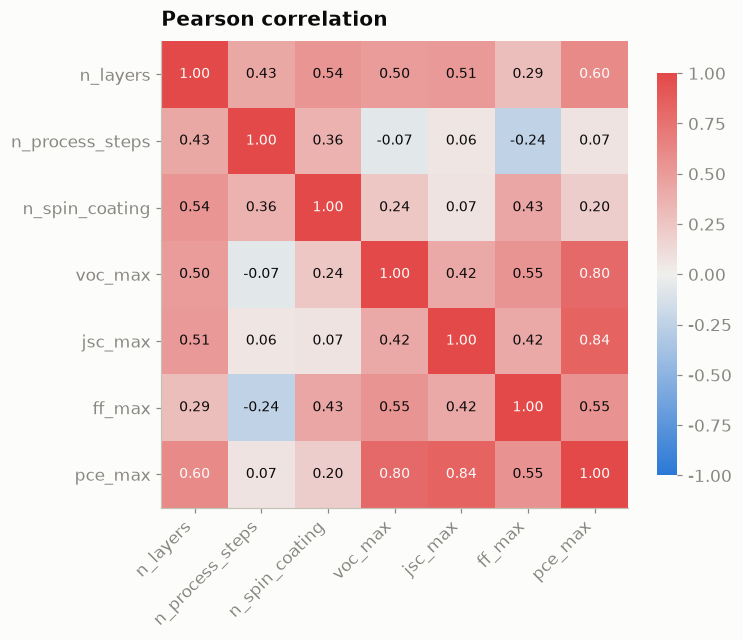

In [11]:
num = ["n_layers","n_process_steps","n_spin_coating","voc_max","jsc_max","ff_max","pce_max"]
corr = ml[num].corr()
fig, ax = plt.subplots(figsize=(7,6))
im = ax.imshow(corr, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(num))); ax.set_xticklabels(num, rotation=45, ha="right")
ax.set_yticks(range(len(num))); ax.set_yticklabels(num)
for i in range(len(num)):
    for j in range(len(num)):
        v = corr.iloc[i,j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                color="#fcfcfb" if abs(v)>0.55 else INK, fontsize=9)
ax.grid(False)
cb = fig.colorbar(im, ax=ax, shrink=0.8); cb.outline.set_visible(False)
ax.set_title("Pearson correlation", loc="left", pad=10)
plt.tight_layout(); plt.show()

## ความสัมพันธ์: อะไรขับ PCE?

PCE = Voc × Jsc × FF / Pin — ดูว่าตัวไหนสัมพันธ์กับ PCE มากสุด และ process ส่งผลไหม.

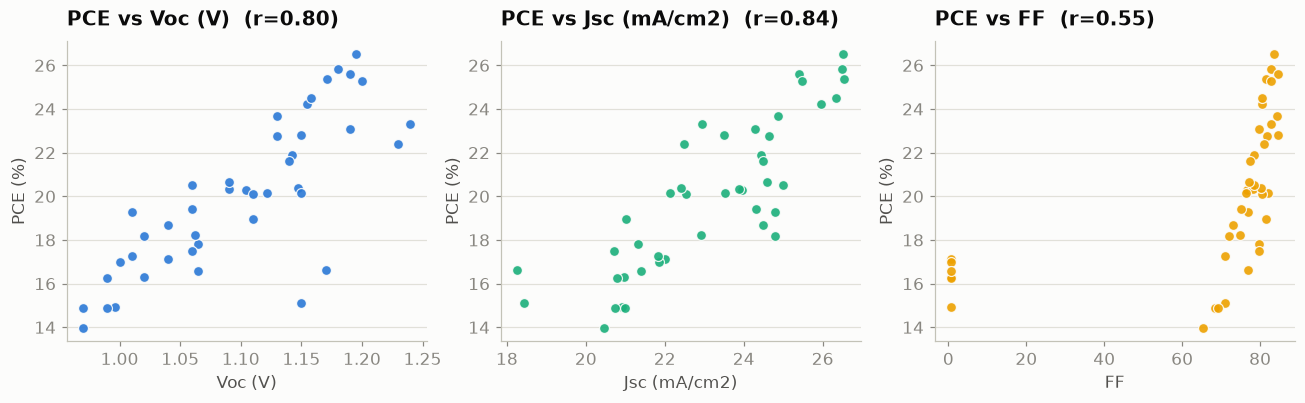

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(12,3.8))
for ax, (x, lab), c in zip(axes, [("voc_max","Voc (V)"),("jsc_max","Jsc (mA/cm2)"),("ff_max","FF")], CAT):
    sub = ml[[x,"pce_max"]].dropna()
    ax.scatter(sub[x], sub["pce_max"], s=42, color=c, edgecolor="#fcfcfb",
               linewidth=0.8, alpha=0.9, zorder=3)
    r = sub[x].corr(sub["pce_max"])
    style(ax, f"PCE vs {lab}  (r={r:.2f})", lab, "PCE (%)")
plt.tight_layout(); plt.show()

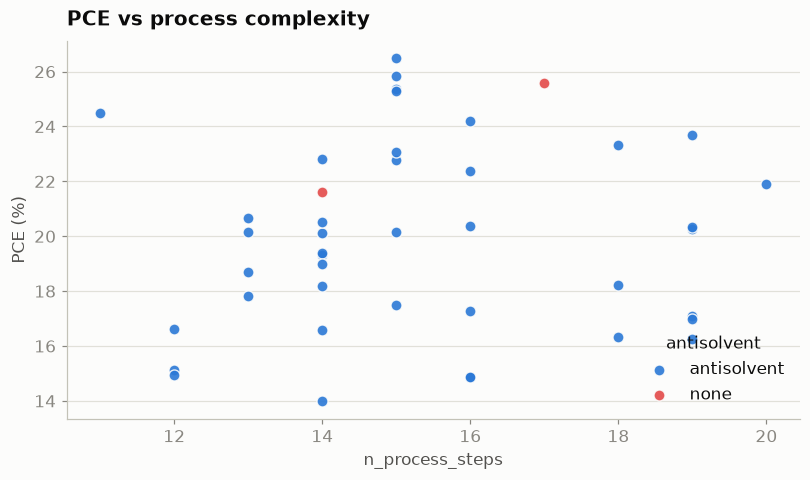

In [13]:
# PCE vs process complexity — do more steps mean higher PCE?
sub = ml[["n_process_steps","pce_max","has_antisolvent"]].dropna()
fig, ax = plt.subplots(figsize=(7.5,4.5))
for flag, c, lab in [(True, CAT[0], "antisolvent"), (False, CAT[5], "none")]:
    s = sub[sub["has_antisolvent"]==flag]
    ax.scatter(s["n_process_steps"], s["pce_max"], s=52, color=c,
               edgecolor="#fcfcfb", linewidth=0.9, alpha=0.9, zorder=3, label=lab)
ax.legend(frameon=False, loc="lower right", title="antisolvent")
style(ax, "PCE vs process complexity", "n_process_steps", "PCE (%)")
plt.tight_layout(); plt.show()

## PCE ที่ดีที่สุดต่อ publication

HTL ในชุดข้อมูลนี้เกือบทั้งหมดเป็น **NiOx (~95%)** จึงเทียบ "ชนิด HTL" ไม่ได้ —
ตัวมันเองก็เป็น insight ว่า dataset ยังกระจุกตัว. แทนที่ด้วยการดู best-PCE ราย paper
(แต่ละ paper = สูตร/กระบวนการหนึ่ง).

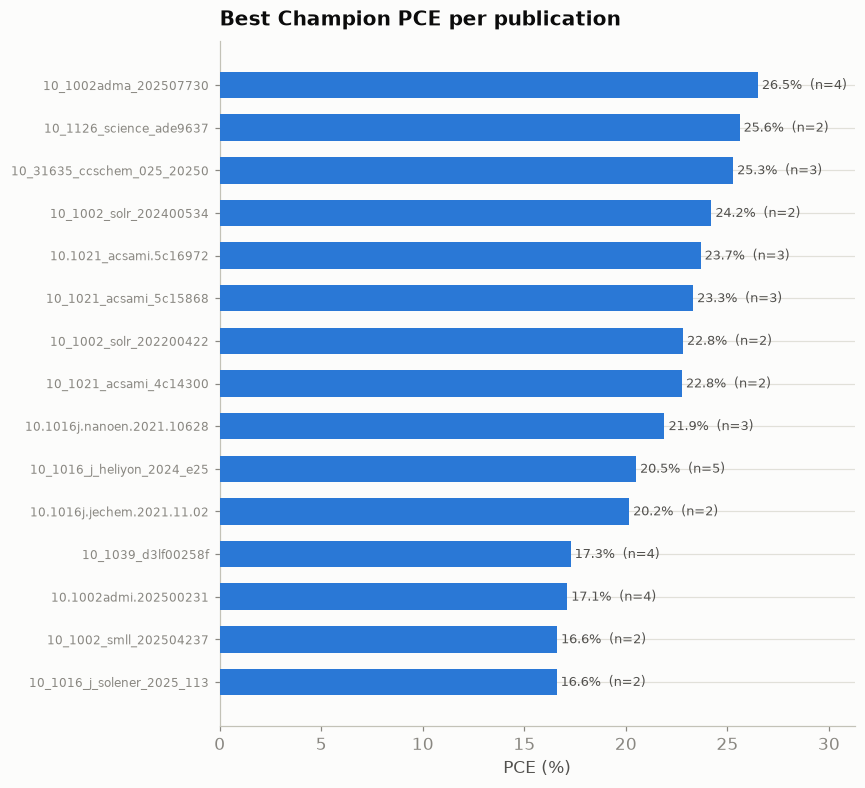

In [14]:
best = (ml.dropna(subset=["pce_max"])
          .groupby("doi_raw")
          .agg(best_pce=("pce_max","max"), n=("device_id","size"))
          .sort_values("best_pce"))
fig, ax = plt.subplots(figsize=(8, 0.42*len(best)+1))
ax.barh(range(len(best)), best["best_pce"], color=BLUE, height=0.62, zorder=3)
ax.set_yticks(range(len(best)))
ax.set_yticklabels([d[:26] for d in best.index], fontsize=8)
for y, (v, n) in enumerate(zip(best["best_pce"], best["n"])):
    ax.text(v+0.2, y, f"{v:.1f}%  (n={n})", va="center", color=INK2, fontsize=8.5)
ax.set_xlim(0, best["best_pce"].max()*1.18)
style(ax, "Best Champion PCE per publication", "PCE (%)", None)
plt.tight_layout(); plt.show()

## ความเสถียร (Stability)

ข้อมูล stability ยังบางมาก (มีไม่กี่ device ที่รายงานครบ) — ดูเท่าที่มี.

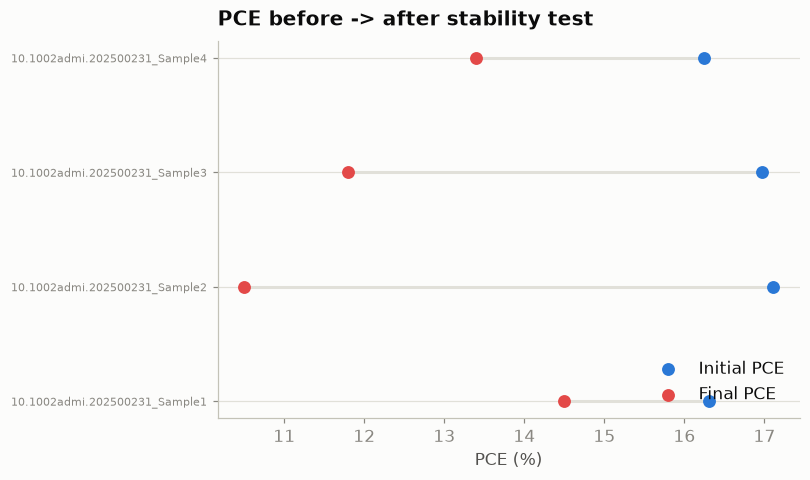

Mean PCE drop: 24.4%

Stability rows reported: 35 devices
device_id        62
environment      62
encapsulation    62
temperature_c    48
humidity_pct     26
time_hr          59
retention_pct    50
t80_hr            0
initial_pce       4
final_pce         4


In [15]:
st = tables["stability"].copy()
have = st.dropna(subset=["initial_pce","final_pce"])
if len(have):
    fig, ax = plt.subplots(figsize=(7.5,4.5))
    y = np.arange(len(have))
    ax.hlines(y, have["final_pce"], have["initial_pce"], color=GRID, lw=2, zorder=2)
    ax.scatter(have["initial_pce"], y, s=55, color=CAT[0], zorder=3, label="Initial PCE")
    ax.scatter(have["final_pce"], y, s=55, color=CAT[5], zorder=3, label="Final PCE")
    ax.set_yticks(y); ax.set_yticklabels(have["device_id"], fontsize=7.5)
    ax.legend(frameon=False, loc="lower right")
    style(ax, "PCE before -> after stability test", "PCE (%)", None)
    plt.tight_layout(); plt.show()
    drop = (1 - have["final_pce"]/have["initial_pce"]).mul(100)
    print("Mean PCE drop: %.1f%%" % drop.mean())
else:
    print("No device has both initial_pce and final_pce yet")
print("\nStability rows reported:", st["device_id"].nunique(), "devices")
print(st.notna().sum().to_string())

## สรุป (Key takeaways)

**ข้อมูล**
- 44 devices / 15 publications; PCE เฉลี่ย ~20% (สูงสุด ~26.5%)
- Voc, Jsc, FF, PCE เก็บได้ค่อนข้างครบ; `bandgap_max` แทบว่าง + ปนความหมาย

**ต้องแก้ก่อนเทรนโมเดล (ยังไม่ได้ clean)**
1. `ff_max` — normalize ให้เป็นหน่วยเดียว (× 100 ถ้าเป็นเศษส่วน)
2. `bandgap_max` — แยก band gap ของ perovskite ออกจาก HTL ก่อนใช้
3. ชื่อวัสดุ (`htl_material`, `perovskite`, …) — รวม synonym (`NiOx`/`NiOx NPs`/`NiOx Nanoparticles`)
4. คอลัมน์ `Parameter`/`unit` ในตาราง process ยังเป็น string ปนหน่วย (`"80,12"`, `"C, hr"`)

**สัญญาณเชิงกระบวนการ**
- FF สัมพันธ์กับ PCE ชัดสุดในบรรดา JV components
- ทุก device ใช้ antisolvent; จำนวนขั้นตอนกระจายตัว ~11–20

**ก้าวต่อไป**: ทำ cleaning layer (แก้ 4 ข้อบน) แล้วค่อยทำ feature engineering / โมเดล
ทำนาย PCE จาก process features.